# MLP — Member 3

**Student:** Thennakoon T.M.A.N  
**IT Number:** IT25100854  
**Dataset:** `maleeshaweerakkody/brain-tumor-mri-preprocessed`  
**Training type:** MLP trained on HOG + GLCM + PCA engineered features

This notebook contains **20 numbered topics** and is designed for the Final Evaluation implementation.


## 1. Project, Member and Model Overview

**Problem:** four-class Brain Tumor MRI classification.

**Classes:** glioma, meningioma, no-tumor and pituitary (the exact folder names are detected automatically).

**Assigned model:** **MLP**

**Final selection rule:** choose the best tuned variety using **Validation Macro F1**, then evaluate that selected variety on the untouched Official Test set.

**Additional validation:** after selecting the better A/B configuration, perform **5-fold stratified cross-validation** using Training data only to measure stability and generalization.


## 2. Model Suitability and Final Evaluation Requirements

### Final Evaluation coverage

This notebook is organized around the implementation-viva requirements:

- **Student:** Thennakoon T.M.A.N — IT25100854
- **Member:** 3
- **Assigned model:** MLP
- **Method:** MLP classification using HOG + GLCM engineered features, StandardScaler and PCA
- **Model suitability:** MLP is suitable because it can learn nonlinear relationships from engineered MRI feature vectors. It provides a useful comparison with convolutional image models.
- **Implementation details:** HOG/GLCM feature extraction, StandardScaler, PCA, TensorFlow/Keras MLP building, optimizer, dropout, callbacks and evaluation are shown in code.
- **Manual parameter tuning:** Variant A and Variant B use different hidden-layer sizes, dropout, regularization and learning-rate settings.
- **Variety comparison:** both varieties are evaluated using Validation Accuracy, Macro Precision, Macro Recall and Macro F1.
- **Validation method:** a stratified hold-out Validation set is used for A/B selection; the selected configuration is then checked with 5-fold stratified cross-validation. The Official Test set remains separate and is used only for final evaluation.
- **Conclusion:** the variety with the highest Validation Macro F1 is selected; 5-fold CV is reported as additional generalization evidence.
- **Limitations/improvements:** included in Topic 20.


## 3. Install Required Libraries

In [ ]:
%pip -q install kagglehub scikit-image scikit-learn joblib

## 4. Import Libraries and Set Reproducibility

In [ ]:
from pathlib import Path
import json
import shutil
import zipfile
import random
import time
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from skimage.color import rgb2gray
from skimage.feature import hog, graycomatrix, graycoprops
from skimage.transform import resize

import joblib
import kagglehub

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

KAGGLE_DATASET = "maleeshaweerakkody/brain-tumor-mri-preprocessed"

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

# Model ownership

MODEL_OWNER = "Thennakoon T.M.A.N"
OWNER_IT_NUMBER = "IT25100854"
OWNER_MEMBER_NO = 3

print("Model Owner:", MODEL_OWNER)
print("IT Number:", OWNER_IT_NUMBER)
print("Assigned Model:", "MLP")


TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Model Owner: Thennakoon T.M.A.N
IT Number: IT25100854
Assigned Model: MLP


## 5. Download the Final Preprocessed Kaggle Dataset

In [ ]:
KAGGLE_ROOT = Path(
    kagglehub.dataset_download(
        KAGGLE_DATASET
    )
)

print("Downloaded dataset:")
print(KAGGLE_ROOT)

WORK = Path(
    "/content/brain_tumor_mlp_svm"
)

DATA_ROOT = (
    WORK
    / "dataset"
)

MODELS_DIR = (
    WORK
    / "models"
)

RESULTS_DIR = (
    WORK
    / "results"
)

for p in [
    WORK,
    MODELS_DIR,
    RESULTS_DIR
]:
    p.mkdir(
        parents=True,
        exist_ok=True
    )

if DATA_ROOT.exists():
    shutil.rmtree(
        DATA_ROOT
    )

DATA_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

zip_files = list(
    KAGGLE_ROOT.rglob(
        "*.zip"
    )
)

if zip_files:
    for zip_path in zip_files:
        print(
            "Extracting:",
            zip_path
        )

        with zipfile.ZipFile(
            zip_path,
            "r"
        ) as z:
            z.extractall(
                DATA_ROOT
            )

    SEARCH_ROOT = DATA_ROOT

else:
    SEARCH_ROOT = KAGGLE_ROOT

print(
    "Search root:",
    SEARCH_ROOT
)

Using Colab cache for faster access to the 'brain-tumor-mri-preprocessed' dataset.
Downloaded dataset:
/kaggle/input/brain-tumor-mri-preprocessed
Search root: /kaggle/input/brain-tumor-mri-preprocessed


## 6. Detect Training, Validation and Official Test Folders

In [ ]:
def find_split_dir(
    root,
    possible_names
):
    names = {
        x.lower()
        for x in possible_names
    }

    matches = [
        p
        for p in root.rglob("*")
        if p.is_dir()
        and p.name.lower() in names
    ]

    if not matches:
        return None

    return sorted(
        matches,
        key=lambda p: (
            -len(
                [
                    x
                    for x in p.iterdir()
                    if x.is_dir()
                ]
            ),
            len(p.parts)
        )
    )[0]


TRAIN_DIR = find_split_dir(
    SEARCH_ROOT,
    ["train", "training"]
)

VAL_DIR = find_split_dir(
    SEARCH_ROOT,
    ["validation", "valid", "val"]
)

TEST_DIR = find_split_dir(
    SEARCH_ROOT,
    ["test", "testing"]
)

print("Training  :", TRAIN_DIR)
print("Validation:", VAL_DIR)
print("Testing   :", TEST_DIR)

assert TRAIN_DIR is not None
assert VAL_DIR is not None
assert TEST_DIR is not None

Training  : /kaggle/input/brain-tumor-mri-preprocessed/train
Validation: /kaggle/input/brain-tumor-mri-preprocessed/validation
Testing   : /kaggle/input/brain-tumor-mri-preprocessed/test


## 7. Exploratory Data Analysis and Class Distribution

Class order: ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


,Class,Training,Validation,Testing
0,glioma_tumor,654,164,100
1,meningioma_tumor,654,163,115
2,no_tumor,654,54,105
3,pituitary_tumor,654,162,74


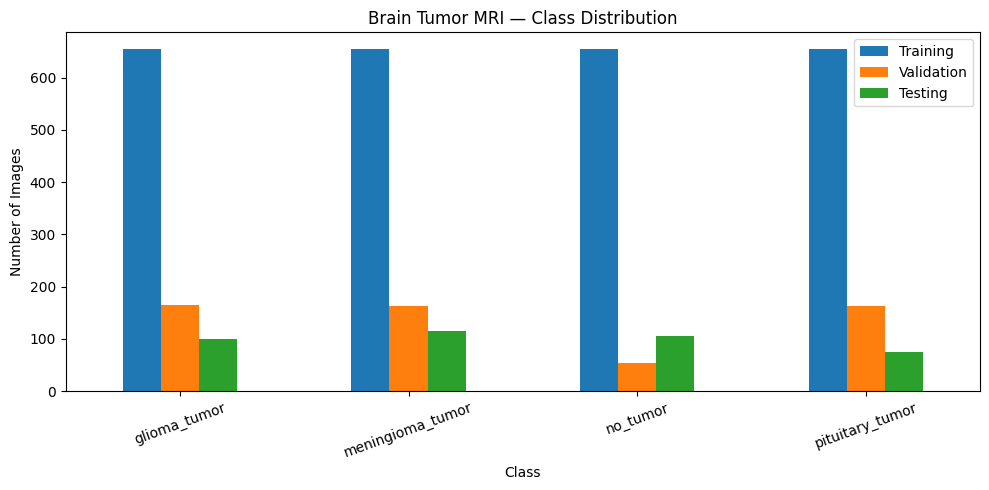

In [ ]:
IMAGE_EXTS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
}


def get_class_names(
    root
):
    return sorted(
        [
            p.name
            for p in root.iterdir()
            if p.is_dir()
        ]
    )


CLASS_NAMES = get_class_names(
    TRAIN_DIR
)

NUM_CLASSES = len(
    CLASS_NAMES
)

print(
    "Class order:",
    CLASS_NAMES
)

assert get_class_names(
    VAL_DIR
) == CLASS_NAMES

assert get_class_names(
    TEST_DIR
) == CLASS_NAMES


def count_images(
    root
):
    rows = []

    for class_name in CLASS_NAMES:
        class_dir = (
            root
            / class_name
        )

        count = sum(
            1
            for p in class_dir.rglob("*")
            if p.is_file()
            and p.suffix.lower()
            in IMAGE_EXTS
        )

        rows.append({
            "Class": class_name,
            "Count": count
        })

    return pd.DataFrame(
        rows
    )


train_counts = count_images(
    TRAIN_DIR
).rename(
    columns={
        "Count": "Training"
    }
)

val_counts = count_images(
    VAL_DIR
).rename(
    columns={
        "Count": "Validation"
    }
)

test_counts = count_images(
    TEST_DIR
).rename(
    columns={
        "Count": "Testing"
    }
)

class_counts = (
    train_counts
    .merge(
        val_counts,
        on="Class"
    )
    .merge(
        test_counts,
        on="Class"
    )
)

display(
    class_counts
)

class_counts.set_index(
    "Class"
)[
    [
        "Training",
        "Validation",
        "Testing"
    ]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title(
    "Brain Tumor MRI — Class Distribution"
)

plt.ylabel(
    "Number of Images"
)

plt.xticks(
    rotation=20
)

plt.tight_layout()
plt.show()

## 8. MLP-Specific Preprocessing / Feature Engineering

```text
Final group-preprocessed MRI
        ↓
Grayscale + 64×64 feature image
        ↓
HOG features
+
GLCM texture features
        ↓
1769 combined features
        ↓
StandardScaler (fit on Training only)
        ↓
PCA 95% variance (fit on Training only)
        ↓
MLP
```

The final Kaggle images already contain the group's earlier resize/padding and CLAHE preprocessing, so CLAHE is not applied again here.

In [ ]:
FEATURE_IMAGE_SIZE = (
    64,
    64
)

HOG_ORIENTATIONS = 9
HOG_PIXELS_PER_CELL = (
    8,
    8
)
HOG_CELLS_PER_BLOCK = (
    2,
    2
)

GLCM_DISTANCES = [
    1
]

GLCM_ANGLES = [
    0,
    np.pi / 4,
    np.pi / 2,
    3 * np.pi / 4
]

GLCM_PROPERTIES = [
    "contrast",
    "dissimilarity",
    "homogeneity",
    "energy",
    "correlation"
]

print(
    "Feature image size:",
    FEATURE_IMAGE_SIZE
)

print(
    "HOG orientations:",
    HOG_ORIENTATIONS
)

print(
    "GLCM properties:",
    GLCM_PROPERTIES
)

Feature image size: (64, 64)
HOG orientations: 9
GLCM properties: ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation']


## 9. Extract HOG + GLCM Features from Train / Validation / Test

In [ ]:
def load_for_features(
    image_path
):
    image = (
        Image.open(
            image_path
        )
        .convert(
            "RGB"
        )
    )

    image = np.asarray(
        image,
        dtype=np.uint8
    )

    # This is a model-feature preparation step only.
    # The final Kaggle image has already received the group's
    # resize/padding + CLAHE preprocessing.
    gray = rgb2gray(
        image
    )

    gray64 = resize(
        gray,
        FEATURE_IMAGE_SIZE,
        anti_aliasing=True
    )

    gray64_uint8 = np.clip(
        gray64 * 255.0,
        0,
        255
    ).astype(
        np.uint8
    )

    return (
        image,
        gray64,
        gray64_uint8
    )


def extract_hog_glcm(
    image_path
):
    _, gray64, gray64_uint8 = (
        load_for_features(
            image_path
        )
    )

    hog_features = hog(
        gray64,
        orientations=HOG_ORIENTATIONS,
        pixels_per_cell=HOG_PIXELS_PER_CELL,
        cells_per_block=HOG_CELLS_PER_BLOCK,
        block_norm="L2-Hys",
        feature_vector=True
    )

    glcm = graycomatrix(
        gray64_uint8,
        distances=GLCM_DISTANCES,
        angles=GLCM_ANGLES,
        levels=256,
        symmetric=True,
        normed=True
    )

    # Average each GLCM property across the four angles.
    glcm_features = np.array(
        [
            graycoprops(
                glcm,
                prop
            ).mean()
            for prop in GLCM_PROPERTIES
        ],
        dtype=np.float32
    )

    combined = np.concatenate(
        [
            hog_features.astype(
                np.float32
            ),
            glcm_features
        ]
    )

    return combined


def collect_split(
    root
):
    X = []
    y = []
    paths = []

    for class_index, class_name in enumerate(
        CLASS_NAMES
    ):
        class_dir = (
            root
            / class_name
        )

        image_paths = sorted(
            [
                p
                for p in class_dir.rglob("*")
                if p.is_file()
                and p.suffix.lower()
                in IMAGE_EXTS
            ]
        )

        for image_path in image_paths:
            X.append(
                extract_hog_glcm(
                    image_path
                )
            )

            y.append(
                class_index
            )

            paths.append(
                str(
                    image_path
                )
            )

    return (
        np.asarray(
            X,
            dtype=np.float32
        ),
        np.asarray(
            y,
            dtype=np.int64
        ),
        paths
    )


start = time.time()

X_train_raw, y_train, train_paths = collect_split(
    TRAIN_DIR
)

X_val_raw, y_val, val_paths = collect_split(
    VAL_DIR
)

X_test_raw, y_test, test_paths = collect_split(
    TEST_DIR
)

print(
    "Feature extraction time:",
    round(
        time.time() - start,
        2
    ),
    "seconds"
)

print(
    "Training feature shape:",
    X_train_raw.shape
)

print(
    "Validation feature shape:",
    X_val_raw.shape
)

print(
    "Testing feature shape:",
    X_test_raw.shape
)

print(
    "Combined HOG + GLCM features per image:",
    X_train_raw.shape[
        1
    ]
)

assert (
    X_train_raw.shape[
        1
    ]
    == 1769
), (
    "Expected 1769 HOG+GLCM features. "
    f"Got {X_train_raw.shape[1]}."
)

Feature extraction time: 164.68 seconds
Training feature shape: (2616, 1769)
Validation feature shape: (543, 1769)
Testing feature shape: (394, 1769)
Combined HOG + GLCM features per image: 1769


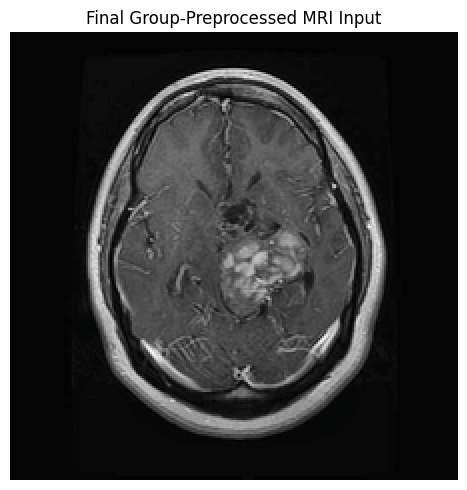

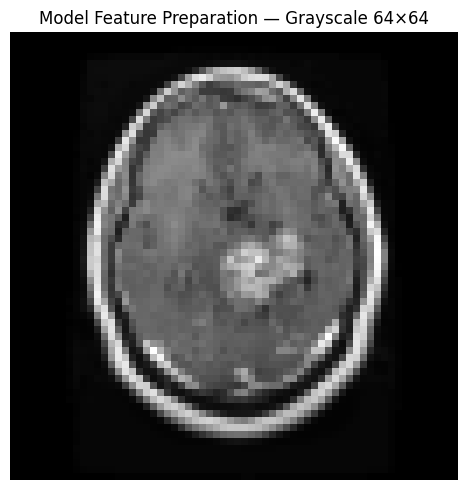

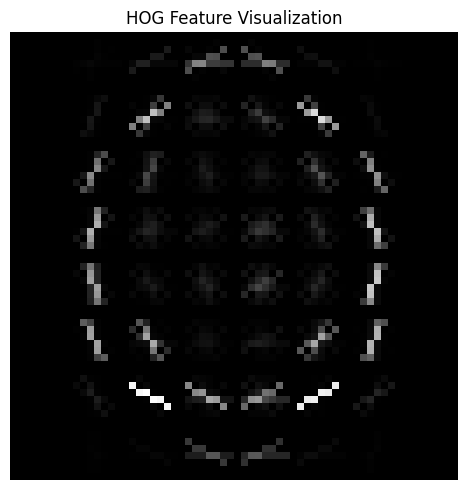

GLCM feature values:


,contrast,dissimilarity,homogeneity,energy,correlation
0,710.419578,11.91013,0.473145,0.294613,0.827161


In [ ]:
sample_path = Path(
    train_paths[
        0
    ]
)

original_rgb, gray64, gray64_uint8 = load_for_features(
    sample_path
)

hog_vector, hog_image = hog(
    gray64,
    orientations=HOG_ORIENTATIONS,
    pixels_per_cell=HOG_PIXELS_PER_CELL,
    cells_per_block=HOG_CELLS_PER_BLOCK,
    block_norm="L2-Hys",
    visualize=True,
    feature_vector=True
)

plt.figure(
    figsize=(6, 5)
)

plt.imshow(
    original_rgb
)

plt.title(
    "Final Group-Preprocessed MRI Input"
)

plt.axis(
    "off"
)

plt.tight_layout()
plt.show()


plt.figure(
    figsize=(6, 5)
)

plt.imshow(
    gray64,
    cmap="gray"
)

plt.title(
    "Model Feature Preparation — Grayscale 64×64"
)

plt.axis(
    "off"
)

plt.tight_layout()
plt.show()


plt.figure(
    figsize=(6, 5)
)

plt.imshow(
    hog_image,
    cmap="gray"
)

plt.title(
    "HOG Feature Visualization"
)

plt.axis(
    "off"
)

plt.tight_layout()
plt.show()


glcm_demo = graycomatrix(
    gray64_uint8,
    distances=GLCM_DISTANCES,
    angles=GLCM_ANGLES,
    levels=256,
    symmetric=True,
    normed=True
)

glcm_demo_values = {
    prop: float(
        graycoprops(
            glcm_demo,
            prop
        ).mean()
    )
    for prop in GLCM_PROPERTIES
}

print(
    "GLCM feature values:"
)

display(
    pd.DataFrame(
        [
            glcm_demo_values
        ]
    )
)

## 10. StandardScaler + PCA — Leakage-Safe Preprocessing

Both `StandardScaler` and PCA are **fit only on Training features**. Validation and Test are transformed using the already-fitted objects.

Original feature count: 1769
PCA feature count: 416
Explained variance retained: 0.9500168561935425


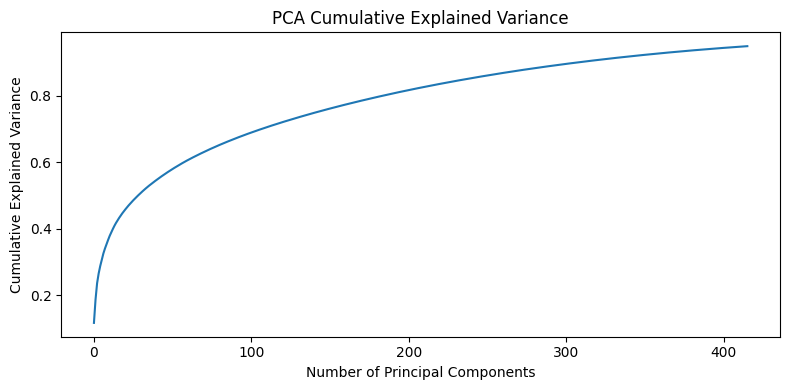

Saved scaler: /content/brain_tumor_mlp_svm/models/hog_glcm_standard_scaler.joblib
Saved PCA: /content/brain_tumor_mlp_svm/models/hog_glcm_pca_95.joblib
MLP one-hot Training labels: (2616, 4)
MLP one-hot Validation labels: (543, 4)


In [ ]:

# LEAKAGE-SAFE FEATURE NORMALIZATION + PCA
# Fit ONLY on Training data.

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_raw
)

X_val_scaled = scaler.transform(
    X_val_raw
)

X_test_scaled = scaler.transform(
    X_test_raw
)


pca = PCA(
    n_components=0.95,
    svd_solver="full"
)

X_train = pca.fit_transform(
    X_train_scaled
)

X_val = pca.transform(
    X_val_scaled
)

X_test = pca.transform(
    X_test_scaled
)

print(
    "Original feature count:",
    X_train_raw.shape[
        1
    ]
)

print(
    "PCA feature count:",
    X_train.shape[
        1
    ]
)

print(
    "Explained variance retained:",
    float(
        pca.explained_variance_ratio_.sum()
    )
)


plt.figure(
    figsize=(8, 4)
)

plt.plot(
    np.cumsum(
        pca.explained_variance_ratio_
    )
)

plt.title(
    "PCA Cumulative Explained Variance"
)

plt.xlabel(
    "Number of Principal Components"
)

plt.ylabel(
    "Cumulative Explained Variance"
)

plt.tight_layout()
plt.show()


SCALER_PATH = (
    MODELS_DIR
    / "hog_glcm_standard_scaler.joblib"
)

PCA_PATH = (
    MODELS_DIR
    / "hog_glcm_pca_95.joblib"
)

joblib.dump(
    scaler,
    SCALER_PATH
)

joblib.dump(
    pca,
    PCA_PATH
)

print(
    "Saved scaler:",
    SCALER_PATH
)

print(
    "Saved PCA:",
    PCA_PATH
)

# One-hot labels are used only for Keras MLP training so
# tf.keras.metrics.F1Score can calculate Macro F1 correctly.
# Integer y_train / y_val / y_test are retained for sklearn evaluation.

Y_train_mlp = tf.keras.utils.to_categorical(
    y_train,
    num_classes=NUM_CLASSES
)

Y_val_mlp = tf.keras.utils.to_categorical(
    y_val,
    num_classes=NUM_CLASSES
)

Y_test_mlp = tf.keras.utils.to_categorical(
    y_test,
    num_classes=NUM_CLASSES
)

print("MLP one-hot Training labels:", Y_train_mlp.shape)
print("MLP one-hot Validation labels:", Y_val_mlp.shape)


## 11. Manual Hyperparameter Tuning Plan

**Variant A — Baseline MLP**
- Hidden layers: 128 → 64
- Dropout: 0.30
- Learning rate: 0.001

**Variant B — Regularized Deep MLP**
- Hidden layers: 256 → 128 → 64
- Batch Normalization
- Dropout: 0.40
- Learning rate: 0.0003

The winning variant is selected using **Validation Macro F1**.

### Variant names used in this project
- **Variant A — Baseline MLP**
- **Variant B — Regularized Deep MLP**


## 12. Build the Two MLP Variants

In [ ]:
MODEL_NAME = "MLP"

VARIANT_NAMES = {
    "A": "Baseline MLP",
    "B": "Regularized Deep MLP",
}

VARIANTS = {
    "A": {
        "hidden_units": [
            128,
            64
        ],
        "dropout": 0.30,
        "learning_rate": 1e-3,
        "batch_norm": False,
    },

    "B": {
        "hidden_units": [
            256,
            128,
            64
        ],
        "dropout": 0.40,
        "learning_rate": 3e-4,
        "batch_norm": True,
    },
}


def new_macro_f1():
    return tf.keras.metrics.F1Score(
        average="macro",
        name="f1_macro"
    )


def build_mlp(
    variant_name
):
    config = VARIANTS[
        variant_name
    ]

    inputs = keras.Input(
        shape=(
            X_train.shape[
                1
            ],
        )
    )

    x = inputs

    for units in config[
        "hidden_units"
    ]:
        x = layers.Dense(
            units,
            activation="relu"
        )(x)

        if config[
            "batch_norm"
        ]:
            x = layers.BatchNormalization()(x)

        x = layers.Dropout(
            config[
                "dropout"
            ]
        )(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = keras.Model(
        inputs,
        outputs,
        name=(
            f"MLP_"
            f"Variant_"
            f"{variant_name}"
        )
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=config[
                "learning_rate"
            ]
        ),
        loss=keras.losses.CategoricalCrossentropy(),
        metrics=[
            "accuracy",
            new_macro_f1()
        ]
    )

    return (
        model,
        config
    )

## 13. Train Variant A Separately — Baseline MLP

In [ ]:
VARIANT_A_NAME = VARIANT_NAMES[
    "A"
]

print(
    "TRAINING MLP VARIANT A —",
    VARIANT_A_NAME
)

mlp_a, config_a = build_mlp(
    "A"
)

MLP_A_PATH = (
    MODELS_DIR
    / "mlp_variant_A_best.keras"
)

callbacks_a = [
    keras.callbacks.ModelCheckpoint(
        MLP_A_PATH,
        monitor="val_f1_macro",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_f1_macro",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    )
]

history_a = mlp_a.fit(
    X_train,
    Y_train_mlp,
    validation_data=(
        X_val,
        Y_val_mlp
    ),
    epochs=80,
    batch_size=32,
    callbacks=callbacks_a,
    verbose=1
)

history_a_df = pd.DataFrame(
    history_a.history
)

best_mlp_a = (
    keras.models.load_model(
        MLP_A_PATH
    )
)

a_val_probs = (
    best_mlp_a.predict(
        X_val,
        verbose=0
    )
)

a_val_pred = np.argmax(
    a_val_probs,
    axis=1
)

MLP_A_METRICS = {
    "Variant": "A",
    "Variant Name": VARIANT_A_NAME,
    "Validation Accuracy": float(
        accuracy_score(
            y_val,
            a_val_pred
        )
    ),
    "Validation Precision": float(
        precision_score(
            y_val,
            a_val_pred,
            average="macro",
            zero_division=0
        )
    ),
    "Validation Recall": float(
        recall_score(
            y_val,
            a_val_pred,
            average="macro",
            zero_division=0
        )
    ),
    "Validation F1": float(
        f1_score(
            y_val,
            a_val_pred,
            average="macro",
            zero_division=0
        )
    ),
}

display(
    pd.DataFrame([
        MLP_A_METRICS
    ])
)

TRAINING MLP VARIANT A — Baseline MLP
Epoch 1/80
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.3625 - f1_macro: 0.3573 - loss: 2.0422
Epoch 1: val_f1_macro improved from None to 0.67200, saving model to /content/brain_tumor_mlp_svm/models/mlp_variant_A_best.keras

Epoch 1: finished saving model to /content/brain_tumor_mlp_svm/models/mlp_variant_A_best.keras
82/82 ━━━━━━━━━━━━━━━━━━━━ 9s 63ms/step - accuracy: 0.4381 - f1_macro: 0.4379 - loss: 1.6204 - val_accuracy: 0.6814 - val_f1_macro: 0.6720 - val_loss: 0.8168 - learning_rate: 0.0010
Epoch 2/80
62/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6378 - f1_macro: 0.6364 - loss: 0.9000
Epoch 2: val_f1_macro improved from 0.67200 to 0.74413, saving model to /content/brain_tumor_mlp_svm/models/mlp_variant_A_best.keras

Epoch 2: finished saving model to /content/brain_tumor_mlp_svm/models/mlp_variant_A_best.keras
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6632 - f1_macro: 0.6616 - loss: 0.8309 - val_accuracy: 0.7532 - v

,Variant,Variant Name,Validation Accuracy,Validation Precision,Validation Recall,Validation F1
0,A,Baseline MLP,0.845304,0.833394,0.849653,0.839876


## 14. Variant A Visualization — Accuracy, Loss and Macro F1

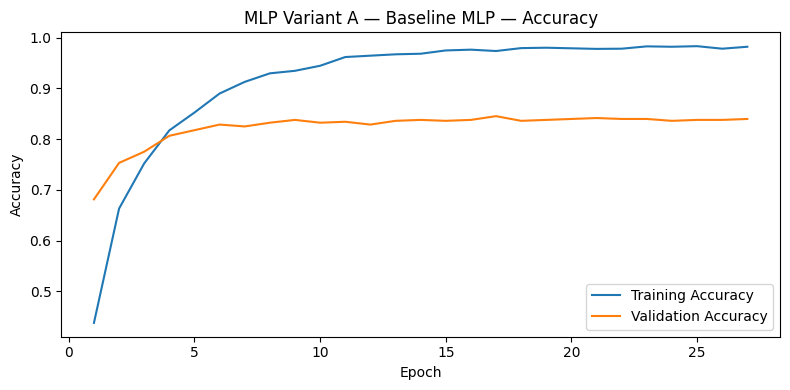

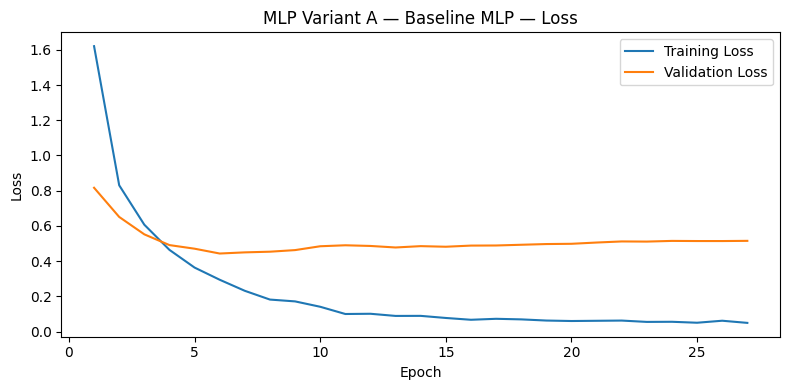

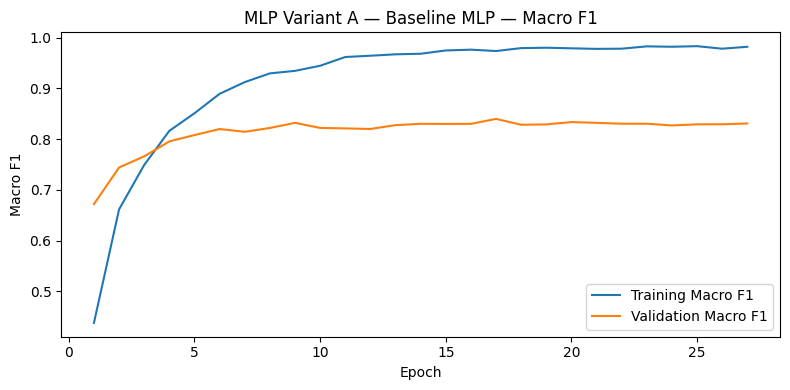

In [ ]:
epochs = np.arange(
    1,
    len(history_a_df) + 1
)

plt.figure(
    figsize=(8, 4)
)

plt.plot(
    epochs,
    history_a_df[
        "accuracy"
    ],
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history_a_df[
        "val_accuracy"
    ],
    label="Validation Accuracy"
)

plt.title(
    "MLP Variant A — Baseline MLP — Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


plt.figure(
    figsize=(8, 4)
)

plt.plot(
    epochs,
    history_a_df[
        "loss"
    ],
    label="Training Loss"
)

plt.plot(
    epochs,
    history_a_df[
        "val_loss"
    ],
    label="Validation Loss"
)

plt.title(
    "MLP Variant A — Baseline MLP — Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()


plt.figure(
    figsize=(8, 4)
)

plt.plot(
    epochs,
    history_a_df[
        "f1_macro"
    ],
    label="Training Macro F1"
)

plt.plot(
    epochs,
    history_a_df[
        "val_f1_macro"
    ],
    label="Validation Macro F1"
)

plt.title(
    "MLP Variant A — Baseline MLP — Macro F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.legend()
plt.tight_layout()
plt.show()

## 15. Train Variant B Separately — Regularized Deep MLP

In [ ]:
VARIANT_B_NAME = VARIANT_NAMES[
    "B"
]

print(
    "TRAINING MLP VARIANT B —",
    VARIANT_B_NAME
)

mlp_b, config_b = build_mlp(
    "B"
)

MLP_B_PATH = (
    MODELS_DIR
    / "mlp_variant_B_best.keras"
)

callbacks_b = [
    keras.callbacks.ModelCheckpoint(
        MLP_B_PATH,
        monitor="val_f1_macro",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_f1_macro",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    )
]

history_b = mlp_b.fit(
    X_train,
    Y_train_mlp,
    validation_data=(
        X_val,
        Y_val_mlp
    ),
    epochs=80,
    batch_size=32,
    callbacks=callbacks_b,
    verbose=1
)

history_b_df = pd.DataFrame(
    history_b.history
)

best_mlp_b = (
    keras.models.load_model(
        MLP_B_PATH
    )
)

b_val_probs = (
    best_mlp_b.predict(
        X_val,
        verbose=0
    )
)

b_val_pred = np.argmax(
    b_val_probs,
    axis=1
)

MLP_B_METRICS = {
    "Variant": "B",
    "Variant Name": VARIANT_B_NAME,
    "Validation Accuracy": float(
        accuracy_score(
            y_val,
            b_val_pred
        )
    ),
    "Validation Precision": float(
        precision_score(
            y_val,
            b_val_pred,
            average="macro",
            zero_division=0
        )
    ),
    "Validation Recall": float(
        recall_score(
            y_val,
            b_val_pred,
            average="macro",
            zero_division=0
        )
    ),
    "Validation F1": float(
        f1_score(
            y_val,
            b_val_pred,
            average="macro",
            zero_division=0
        )
    ),
}

display(
    pd.DataFrame([
        MLP_B_METRICS
    ])
)

TRAINING MLP VARIANT B — Regularized Deep MLP
Epoch 1/80
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.2876 - f1_macro: 0.2836 - loss: 2.0133
Epoch 1: val_f1_macro improved from None to 0.48119, saving model to /content/brain_tumor_mlp_svm/models/mlp_variant_B_best.keras

Epoch 1: finished saving model to /content/brain_tumor_mlp_svm/models/mlp_variant_B_best.keras
82/82 ━━━━━━━━━━━━━━━━━━━━ 12s 82ms/step - accuracy: 0.2993 - f1_macro: 0.2977 - loss: 1.9318 - val_accuracy: 0.5359 - val_f1_macro: 0.4812 - val_loss: 1.1077 - learning_rate: 3.0000e-04
Epoch 2/80
81/82 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3880 - f1_macro: 0.3844 - loss: 1.5608
Epoch 2: val_f1_macro improved from 0.48119 to 0.60966, saving model to /content/brain_tumor_mlp_svm/models/mlp_variant_B_best.keras

Epoch 2: finished saving model to /content/brain_tumor_mlp_svm/models/mlp_variant_B_best.keras
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.4094 - f1_macro: 0.4073 - loss: 1.5178 - val_accura

,Variant,Variant Name,Validation Accuracy,Validation Precision,Validation Recall,Validation F1
0,B,Regularized Deep MLP,0.85267,0.832707,0.861989,0.844306


## 16. Variant B Visualization — Accuracy, Loss and Macro F1

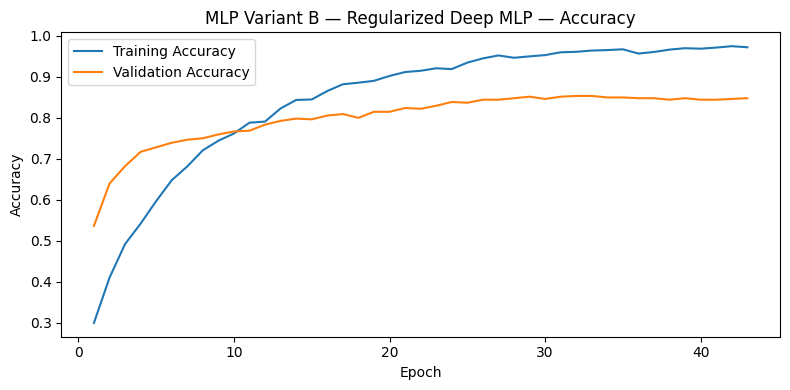

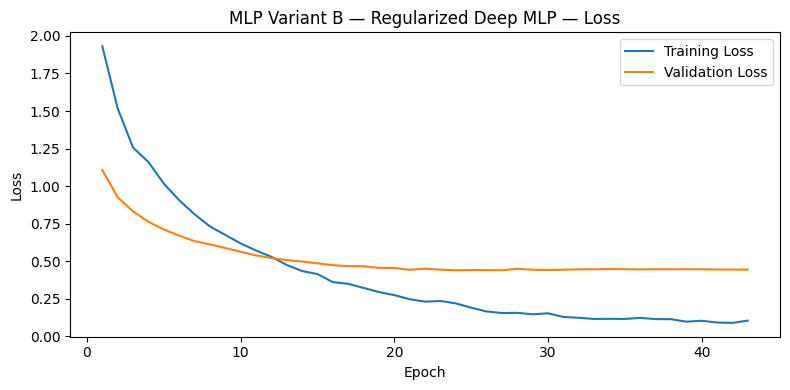

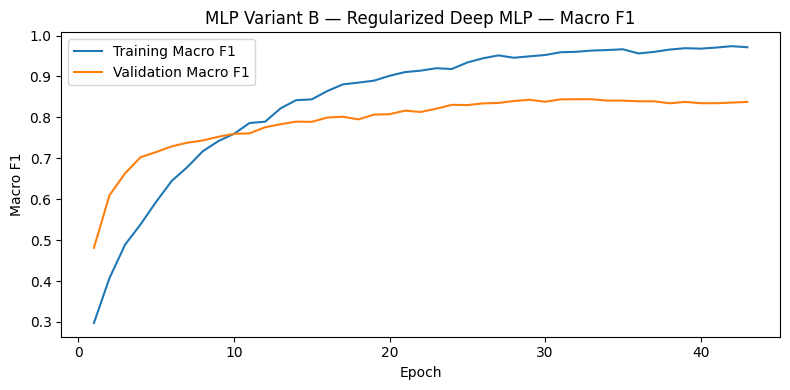

In [ ]:
epochs = np.arange(
    1,
    len(history_b_df) + 1
)

plt.figure(
    figsize=(8, 4)
)

plt.plot(
    epochs,
    history_b_df[
        "accuracy"
    ],
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history_b_df[
        "val_accuracy"
    ],
    label="Validation Accuracy"
)

plt.title(
    "MLP Variant B — Regularized Deep MLP — Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


plt.figure(
    figsize=(8, 4)
)

plt.plot(
    epochs,
    history_b_df[
        "loss"
    ],
    label="Training Loss"
)

plt.plot(
    epochs,
    history_b_df[
        "val_loss"
    ],
    label="Validation Loss"
)

plt.title(
    "MLP Variant B — Regularized Deep MLP — Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()


plt.figure(
    figsize=(8, 4)
)

plt.plot(
    epochs,
    history_b_df[
        "f1_macro"
    ],
    label="Training Macro F1"
)

plt.plot(
    epochs,
    history_b_df[
        "val_f1_macro"
    ],
    label="Validation Macro F1"
)

plt.title(
    "MLP Variant B — Regularized Deep MLP — Macro F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.legend()
plt.tight_layout()
plt.show()

## 17. Compare Variant A vs Variant B and Select the Best MLP

,Variant,Variant Name,Validation Accuracy,Validation Precision,Validation Recall,Validation F1
0,B,Regularized Deep MLP,0.852670,0.832707,0.861989,0.844306
1,A,Baseline MLP,0.845304,0.833394,0.849653,0.839876


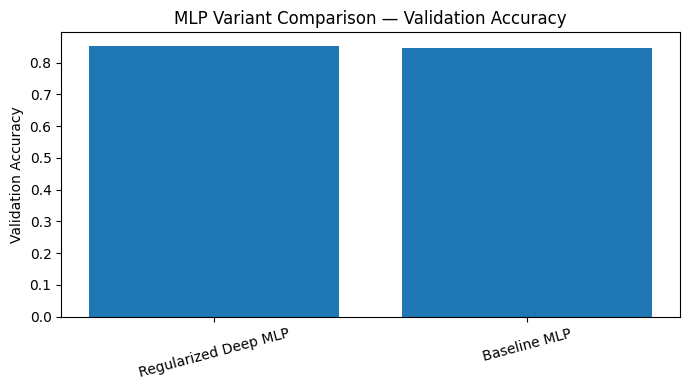

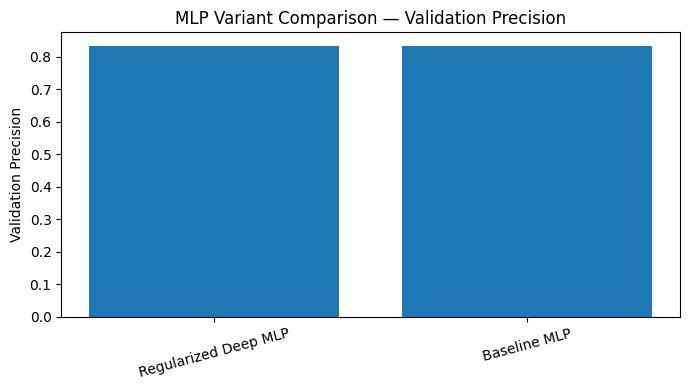

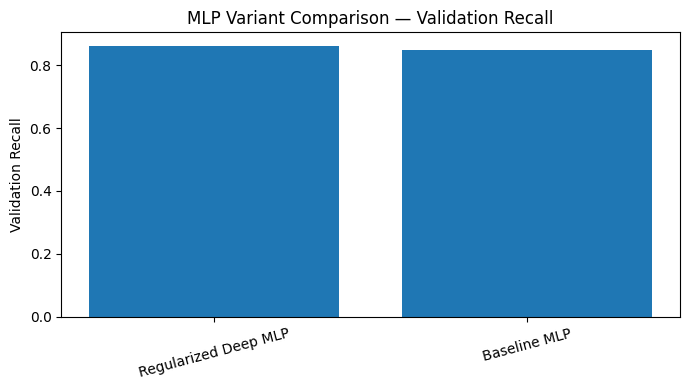

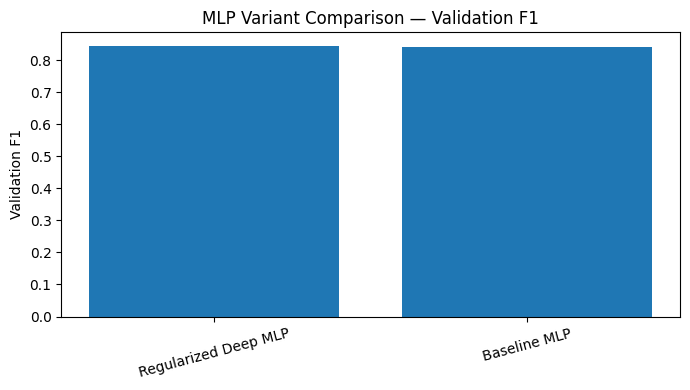

Selected Variant: B — Regularized Deep MLP
Selection metric: Highest Validation Macro F1


In [ ]:
variant_results = pd.DataFrame([
    MLP_A_METRICS,
    MLP_B_METRICS
]).sort_values(
    "Validation F1",
    ascending=False
).reset_index(
    drop=True
)

display(
    variant_results
)

for metric_name in [
    "Validation Accuracy",
    "Validation Precision",
    "Validation Recall",
    "Validation F1"
]:
    plt.figure(
        figsize=(7, 4)
    )

    plt.bar(
        variant_results[
            "Variant Name"
        ],
        variant_results[
            metric_name
        ]
    )

    plt.title(
        f"MLP Variant Comparison — {metric_name}"
    )

    plt.ylabel(
        metric_name
    )

    plt.xticks(
        rotation=15
    )

    plt.tight_layout()
    plt.show()


BEST_VARIANT = str(
    variant_results.loc[
        0,
        "Variant"
    ]
)

BEST_VARIANT_NAME = str(
    variant_results.loc[
        0,
        "Variant Name"
    ]
)

if BEST_VARIANT == "A":
    BEST_MLP_CHECKPOINT = MLP_A_PATH
else:
    BEST_MLP_CHECKPOINT = MLP_B_PATH

FINAL_MODEL_PATH = (
    MODELS_DIR
    / "it25100854_mlp_selected.keras"
)

shutil.copy2(
    BEST_MLP_CHECKPOINT,
    FINAL_MODEL_PATH
)

print(
    "Selected Variant:",
    BEST_VARIANT,
    "—",
    BEST_VARIANT_NAME
)

print(
    "Selection metric:",
    "Highest Validation Macro F1"
)

## 18. 5-Fold Stratified Cross-Validation — Selected Variant

The selected Variant A/B configuration is evaluated using **5-fold stratified cross-validation on the Training split only**. The model is rebuilt and retrained independently in every fold. The normal held-out Validation set and the Official Test set are not included in these folds.

The output includes Fold 1–5 Accuracy, Macro Precision, Macro Recall and **Macro F1**, plus the Mean CV Macro F1 and standard deviation. The owner-specific summary is exported as `*_5fold_cv_summary.csv` for the final six-model comparison.

> **Report screenshot:** capture the 5-fold summary table and Macro F1 chart after this cell finishes.



5-FOLD CV — FOLD 1/5
Selected variant: B — Regularized Deep MLP
Epoch 1/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 99ms/step - accuracy: 0.3031 - f1_macro: 0.3030 - loss: 2.0559 - val_accuracy: 0.4752 - val_f1_macro: 0.4559 - val_loss: 1.2089 - learning_rate: 3.0000e-04
Epoch 2/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4054 - f1_macro: 0.4037 - loss: 1.5834 - val_accuracy: 0.5897 - val_f1_macro: 0.5759 - val_loss: 0.9819 - learning_rate: 3.0000e-04
Epoch 3/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4833 - f1_macro: 0.4809 - loss: 1.3141 - val_accuracy: 0.6317 - val_f1_macro: 0.6191 - val_loss: 0.8660 - learning_rate: 3.0000e-04
Epoch 4/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5225 - f1_macro: 0.5195 - loss: 1.2283 - val_accuracy: 0.6698 - val_f1_macro: 0.6570 - val_loss: 0.7900 - learning_rate: 3.0000e-04
Epoch 5/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5684 - f1_macro: 0.5628 - loss: 1.1044 - val_accuracy: 0.7004 - val_f1_macro: 0.6873 

,Fold,Accuracy,Macro Precision,Macro Recall,Macro F1
0,1,0.841603,0.843091,0.841603,0.840449
1,2,0.843212,0.842765,0.843467,0.841676
2,3,0.873805,0.871525,0.873943,0.871272
3,4,0.841300,0.839592,0.840854,0.835812
4,5,0.850860,0.851309,0.850940,0.848026


,Member,Owner,IT Number,Model,Selected Variant,Selected Variant Name,Fold 1 F1,Fold 2 F1,Fold 3 F1,Fold 4 F1,Fold 5 F1,Mean CV F1,Std CV F1
0,3,Thennakoon T.M.A.N,IT25100854,MLP,B,Regularized Deep MLP,0.840449,0.841676,0.871272,0.835812,0.848026,0.847447,0.014014


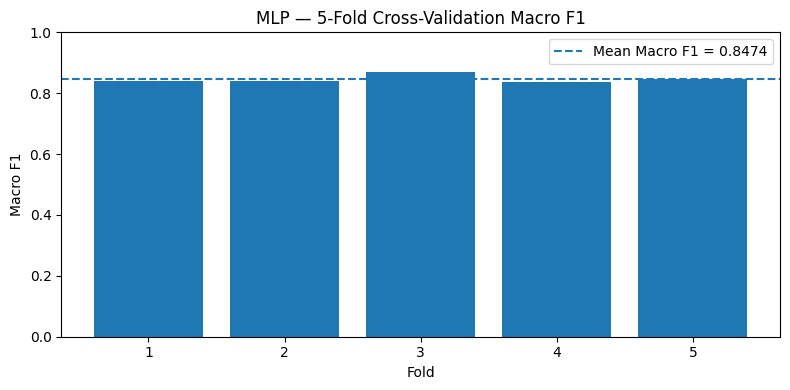

Saved: /content/brain_tumor_mlp_svm/results/it25100854_mlp_5fold_cv_folds.csv
Saved: /content/brain_tumor_mlp_svm/results/it25100854_mlp_5fold_cv_summary.csv


In [ ]:

# 5-FOLD STRATIFIED CROSS-VALIDATION — SELECTED MLP VARIANT
# IMPORTANT:
# - Cross-validation uses Training data only.
# - StandardScaler and PCA are FIT INSIDE each training fold.
# - Official Validation and Official Test remain untouched.


from sklearn.model_selection import StratifiedKFold

CV_N_SPLITS = 5

skf = StratifiedKFold(
    n_splits=CV_N_SPLITS,
    shuffle=True,
    random_state=SEED
)

cv_rows = []

# build_mlp() uses X_train.shape[1], so preserve it.
_ORIGINAL_X_TRAIN = X_train

for fold_no, (fold_train_idx, fold_val_idx) in enumerate(
    skf.split(
        X_train_raw,
        y_train
    ),
    start=1
):
    print(
        "\n"
        + "=" * 80
    )
    print(
        f"5-FOLD CV — FOLD {fold_no}/{CV_N_SPLITS}"
    )
    print(
        "Selected variant:",
        BEST_VARIANT,
        "—",
        BEST_VARIANT_NAME
    )
    print(
        "=" * 80
    )

    X_fold_train_raw = X_train_raw[
        fold_train_idx
    ]

    X_fold_val_raw = X_train_raw[
        fold_val_idx
    ]

    y_fold_train = y_train[
        fold_train_idx
    ]

    y_fold_val = y_train[
        fold_val_idx
    ]

    # Leakage-safe fold preprocessing:
    # fit scaler and PCA only on the current fold's training portion.
    fold_scaler = StandardScaler()

    X_fold_train_scaled = (
        fold_scaler.fit_transform(
            X_fold_train_raw
        )
    )

    X_fold_val_scaled = (
        fold_scaler.transform(
            X_fold_val_raw
        )
    )

    fold_pca = PCA(
        n_components=0.95,
        svd_solver="full"
    )

    X_fold_train = (
        fold_pca.fit_transform(
            X_fold_train_scaled
        )
    )

    X_fold_val = (
        fold_pca.transform(
            X_fold_val_scaled
        )
    )

    # Temporarily expose current fold dimension to build_mlp().
    X_train = X_fold_train

    fold_model, _ = build_mlp(
        BEST_VARIANT
    )

    Y_fold_train = tf.keras.utils.to_categorical(
        y_fold_train,
        num_classes=NUM_CLASSES
    )

    Y_fold_val = tf.keras.utils.to_categorical(
        y_fold_val,
        num_classes=NUM_CLASSES
    )

    fold_callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_f1_macro",
            mode="max",
            patience=10,
            restore_best_weights=True,
            verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=4,
            min_lr=1e-6,
            verbose=1
        )
    ]

    fold_model.fit(
        X_fold_train,
        Y_fold_train,
        validation_data=(
            X_fold_val,
            Y_fold_val
        ),
        epochs=80,
        batch_size=32,
        callbacks=fold_callbacks,
        verbose=1
    )

    fold_probs = fold_model.predict(
        X_fold_val,
        verbose=0
    )

    fold_pred = np.argmax(
        fold_probs,
        axis=1
    )

    cv_rows.append({
        "Fold": fold_no,
        "Accuracy": float(
            accuracy_score(
                y_fold_val,
                fold_pred
            )
        ),
        "Macro Precision": float(
            precision_score(
                y_fold_val,
                fold_pred,
                average="macro",
                zero_division=0
            )
        ),
        "Macro Recall": float(
            recall_score(
                y_fold_val,
                fold_pred,
                average="macro",
                zero_division=0
            )
        ),
        "Macro F1": float(
            f1_score(
                y_fold_val,
                fold_pred,
                average="macro",
                zero_division=0
            )
        ),
    })

    tf.keras.backend.clear_session()

# Restore original transformed Training features.
X_train = _ORIGINAL_X_TRAIN

cv_df = pd.DataFrame(
    cv_rows
)

print(
    "\n5-FOLD CROSS-VALIDATION RESULTS"
)

display(
    cv_df
)

fold_f1 = cv_df[
    "Macro F1"
].to_numpy()

cv_summary = pd.DataFrame([
    {
        "Member": OWNER_MEMBER_NO,
        "Owner": MODEL_OWNER,
        "IT Number": OWNER_IT_NUMBER,
        "Model": MODEL_NAME,
        "Selected Variant": BEST_VARIANT,
        "Selected Variant Name": BEST_VARIANT_NAME,
        "Fold 1 F1": float(fold_f1[0]),
        "Fold 2 F1": float(fold_f1[1]),
        "Fold 3 F1": float(fold_f1[2]),
        "Fold 4 F1": float(fold_f1[3]),
        "Fold 5 F1": float(fold_f1[4]),
        "Mean CV F1": float(
            np.mean(
                fold_f1
            )
        ),
        "Std CV F1": float(
            np.std(
                fold_f1,
                ddof=1
            )
        ),
    }
])

display(
    cv_summary
)

plt.figure(
    figsize=(8, 4)
)

plt.bar(
    cv_df[
        "Fold"
    ].astype(str),
    cv_df[
        "Macro F1"
    ]
)

plt.axhline(
    cv_df[
        "Macro F1"
    ].mean(),
    linestyle="--",
    label=(
        "Mean Macro F1 = "
        f"{cv_df['Macro F1'].mean():.4f}"
    )
)

plt.title(
    "MLP — 5-Fold Cross-Validation Macro F1"
)

plt.xlabel("Fold")
plt.ylabel("Macro F1")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

CV_FOLDS_CSV = (
    RESULTS_DIR
    / "mlp_5fold_cv_folds.csv"
)

CV_SUMMARY_CSV = (
    RESULTS_DIR
    / "mlp_5fold_cv_summary.csv"
)

cv_file_prefix = (
    OWNER_IT_NUMBER.lower()
    + "_"
    + MODEL_NAME.lower().replace(" ", "_")
)

CV_FOLDS_CSV = (
    RESULTS_DIR
    / f"{cv_file_prefix}_5fold_cv_folds.csv"
)

CV_SUMMARY_CSV = (
    RESULTS_DIR
    / f"{cv_file_prefix}_5fold_cv_summary.csv"
)

cv_df.to_csv(
    CV_FOLDS_CSV,
    index=False
)

cv_summary.to_csv(
    CV_SUMMARY_CSV,
    index=False
)

print(
    "Saved:",
    CV_FOLDS_CSV
)

print(
    "Saved:",
    CV_SUMMARY_CSV
)

## 19. Official Test Evaluation, Error Analysis and Export

Only the selected MLP is evaluated on the Official Test set.

Exports include:
- selected `.keras` model,
- StandardScaler `.joblib`,
- PCA `.joblib`,
- final result CSV,
- variant comparison CSV,
- classification report CSV,
- confusion matrix CSV,
- per-class metrics CSV,
- history CSV files,
- metadata JSON.

,Test Accuracy,Test Precision,Test Recall,Test F1
0,0.642132,0.698127,0.642241,0.611649


,precision,recall,f1-score,support
glioma_tumor,0.826087,0.190000,0.308943,100.000000
meningioma_tumor,0.726562,0.808696,0.765432,115.000000
no_tumor,0.509091,0.800000,0.622222,105.000000
pituitary_tumor,0.730769,0.770270,0.750000,74.000000
accuracy,0.642132,0.642132,0.642132,0.642132
macro avg,0.698127,0.642241,0.611649,394.000000
weighted avg,0.694657,0.642132,0.608508,394.000000


,Pred glioma_tumor,Pred meningioma_tumor,Pred no_tumor,Pred pituitary_tumor
True glioma_tumor,19,10,58,13
True meningioma_tumor,1,93,18,3
True no_tumor,3,13,84,5
True pituitary_tumor,0,12,5,57


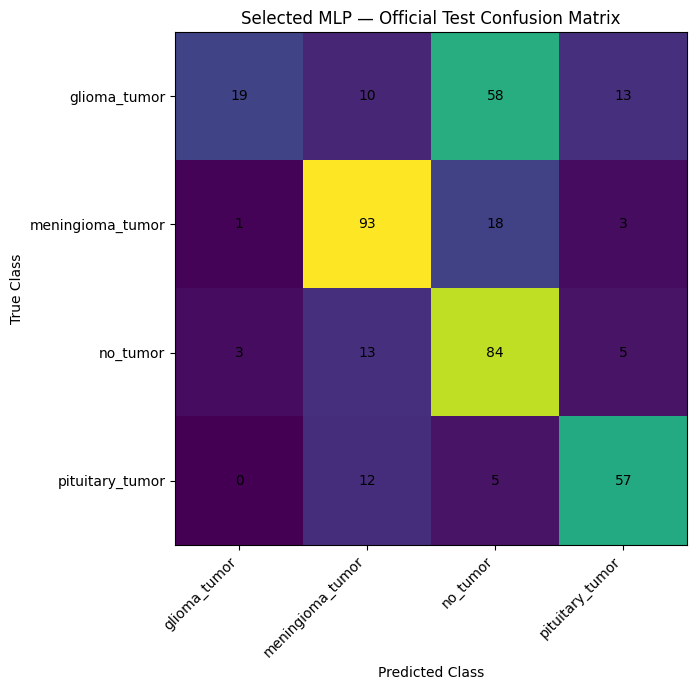

,Class,Precision,Recall,F1,Support
0,glioma_tumor,0.826087,0.190000,0.308943,100
1,meningioma_tumor,0.726562,0.808696,0.765432,115
2,no_tumor,0.509091,0.800000,0.622222,105
3,pituitary_tumor,0.730769,0.770270,0.750000,74


,Member,Student,IT Number,Model,Feature Pipeline,Selected Variant,Selected Variant Name,Validation F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,3,Thennakoon T.M.A.N,IT25100854,MLP,HOG + GLCM + StandardScaler + PCA(95%),B,Regularized Deep MLP,0.844306,0.642132,0.698127,0.642241,0.611649


Saved selected MLP: /content/brain_tumor_mlp_svm/models/it25100854_mlp_selected.keras
Saved scaler: /content/brain_tumor_mlp_svm/models/hog_glcm_standard_scaler.joblib
Saved PCA: /content/brain_tumor_mlp_svm/models/hog_glcm_pca_95.joblib
Saved metadata: /content/brain_tumor_mlp_svm/results/best_model_metadata.json


In [ ]:
best_model = (
    keras.models.load_model(
        FINAL_MODEL_PATH
    )
)

test_probs = (
    best_model.predict(
        X_test,
        verbose=0
    )
)

test_pred = np.argmax(
    test_probs,
    axis=1
)

TEST_METRICS = {
    "Test Accuracy": float(
        accuracy_score(
            y_test,
            test_pred
        )
    ),
    "Test Precision": float(
        precision_score(
            y_test,
            test_pred,
            average="macro",
            zero_division=0
        )
    ),
    "Test Recall": float(
        recall_score(
            y_test,
            test_pred,
            average="macro",
            zero_division=0
        )
    ),
    "Test F1": float(
        f1_score(
            y_test,
            test_pred,
            average="macro",
            zero_division=0
        )
    ),
}

display(
    pd.DataFrame([
        TEST_METRICS
    ])
)

report_dict = classification_report(
    y_test,
    test_pred,
    target_names=CLASS_NAMES,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(
    report_dict
).transpose()

display(
    report_df
)

cm = confusion_matrix(
    y_test,
    test_pred
)

cm_df = pd.DataFrame(
    cm,
    index=[
        f"True {x}"
        for x in CLASS_NAMES
    ],
    columns=[
        f"Pred {x}"
        for x in CLASS_NAMES
    ]
)

display(
    cm_df
)

plt.figure(
    figsize=(8, 7)
)

plt.imshow(
    cm
)

plt.title(
    "Selected MLP — Official Test Confusion Matrix"
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(
    np.arange(
        NUM_CLASSES
    ),
    CLASS_NAMES,
    rotation=45,
    ha="right"
)

plt.yticks(
    np.arange(
        NUM_CLASSES
    ),
    CLASS_NAMES
)

for i in range(
    cm.shape[0]
):
    for j in range(
        cm.shape[1]
    ):
        plt.text(
            j,
            i,
            str(
                cm[i, j]
            ),
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()


per_class_rows = []

for class_name in CLASS_NAMES:
    values = report_dict[
        class_name
    ]

    per_class_rows.append({
        "Class": class_name,
        "Precision": float(
            values[
                "precision"
            ]
        ),
        "Recall": float(
            values[
                "recall"
            ]
        ),
        "F1": float(
            values[
                "f1-score"
            ]
        ),
        "Support": int(
            values[
                "support"
            ]
        ),
    })

per_class_df = pd.DataFrame(
    per_class_rows
)

display(
    per_class_df
)


member_result = pd.DataFrame([
    {
        "Member": OWNER_MEMBER_NO,
        "Student": MODEL_OWNER,
        "IT Number": OWNER_IT_NUMBER,
        "Model": "MLP",
        "Feature Pipeline": "HOG + GLCM + StandardScaler + PCA(95%)",
        "Selected Variant": BEST_VARIANT,
        "Selected Variant Name": BEST_VARIANT_NAME,
        "Validation F1": float(
            variant_results.loc[
                0,
                "Validation F1"
            ]
        ),
        **TEST_METRICS,
    }
])

display(
    member_result
)


FINAL_RESULT_CSV = (
    RESULTS_DIR
    / "it25100854_mlp_final_result.csv"
)

VARIANT_CSV = (
    RESULTS_DIR
    / "it25100854_mlp_variant_comparison.csv"
)

REPORT_CSV = (
    RESULTS_DIR
    / "it25100854_mlp_classification_report.csv"
)

CM_CSV = (
    RESULTS_DIR
    / "it25100854_mlp_confusion_matrix.csv"
)

PER_CLASS_CSV = (
    RESULTS_DIR
    / "it25100854_mlp_per_class_metrics.csv"
)

HISTORY_A_CSV = (
    RESULTS_DIR
    / "it25100854_mlp_history_A.csv"
)

HISTORY_B_CSV = (
    RESULTS_DIR
    / "it25100854_mlp_history_B.csv"
)

member_result.to_csv(
    FINAL_RESULT_CSV,
    index=False
)

variant_results.to_csv(
    VARIANT_CSV,
    index=False
)

report_df.to_csv(
    REPORT_CSV
)

cm_df.to_csv(
    CM_CSV
)

per_class_df.to_csv(
    PER_CLASS_CSV,
    index=False
)

history_a_df.to_csv(
    HISTORY_A_CSV,
    index=False
)

history_b_df.to_csv(
    HISTORY_B_CSV,
    index=False
)


metadata = {
    "model_owner": MODEL_OWNER,
    "owner_it_number": OWNER_IT_NUMBER,
    "owner_member_no": OWNER_MEMBER_NO,
    "member": OWNER_MEMBER_NO,
    "selected_model": "MLP",
    "selected_variant": BEST_VARIANT,
    "selected_variant_name": BEST_VARIANT_NAME,
    "selection_metric": "Validation Macro F1",
    "class_names": CLASS_NAMES,
    "dataset": KAGGLE_DATASET,
    "feature_pipeline": {
        "input": "Final group-preprocessed MRI",
        "grayscale_feature_size": [64, 64],
        "hog_orientations": HOG_ORIENTATIONS,
        "hog_pixels_per_cell": list(
            HOG_PIXELS_PER_CELL
        ),
        "hog_cells_per_block": list(
            HOG_CELLS_PER_BLOCK
        ),
        "glcm_distances": GLCM_DISTANCES,
        "glcm_angles_radians": GLCM_ANGLES,
        "glcm_properties": GLCM_PROPERTIES,
        "raw_feature_count": int(
            X_train_raw.shape[
                1
            ]
        ),
        "pca_components": int(
            X_train.shape[
                1
            ]
        ),
        "pca_variance_retained": float(
            pca.explained_variance_ratio_.sum()
        ),
    },
    "variant_configs": VARIANTS,
    "test_metrics": TEST_METRICS,
}

METADATA_PATH = (
    RESULTS_DIR
    / "best_model_metadata.json"
)

with open(
    METADATA_PATH,
    "w"
) as f:
    json.dump(
        metadata,
        f,
        indent=2
    )

print(
    "Saved selected MLP:",
    FINAL_MODEL_PATH
)

print(
    "Saved scaler:",
    SCALER_PATH
)

print(
    "Saved PCA:",
    PCA_PATH
)

print(
    "Saved metadata:",
    METADATA_PATH
)

## 20. Download Final MLP Package



In [ ]:
from google.colab import files

PACKAGE_DIR = (
    WORK
    / "MLP_FINAL_PACKAGE"
)

if PACKAGE_DIR.exists():
    shutil.rmtree(
        PACKAGE_DIR
    )

PACKAGE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

files_to_package = [
    FINAL_MODEL_PATH,
    SCALER_PATH,
    PCA_PATH,
    FINAL_RESULT_CSV,
    VARIANT_CSV,
    REPORT_CSV,
    CM_CSV,
    PER_CLASS_CSV,
    HISTORY_A_CSV,
    HISTORY_B_CSV,
    METADATA_PATH,
]

for src in files_to_package:
    shutil.copy2(
        src,
        PACKAGE_DIR
        / Path(
            src
        ).name
    )

PACKAGE_ZIP = Path(
    shutil.make_archive(
        "/content/MLP_FINAL_PACKAGE",
        "zip",
        root_dir=PACKAGE_DIR
    )
)

files.download(
    str(
        FINAL_MODEL_PATH
    )
)

files.download(
    str(
        FINAL_RESULT_CSV
    )
)

files.download(
    str(
        VARIANT_CSV
    )
)

files.download(
    str(
        METADATA_PATH
    )
)

files.download(
    str(
        PACKAGE_ZIP
    )
)

# Download 5-fold cross-validation outputs.
if "CV_FOLDS_CSV" in globals():
    files.download(str(CV_FOLDS_CSV))

if "CV_SUMMARY_CSV" in globals():
    files.download(str(CV_SUMMARY_CSV))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>